# LAB 1 — Phân loại chữ số MNIST bằng PyTorch

> **Phiên bản dành cho sinh viên mới học**  
> Notebook này trình bày đầy đủ quy trình xây dựng một bài toán học máy: đọc dữ liệu, khảo sát dữ liệu, chia tập, xây dựng mô hình, huấn luyện, chọn mô hình tốt nhất và đánh giá cuối cùng.

## Mục tiêu học tập

Sau khi hoàn thành notebook, sinh viên có thể:

1. Phân biệt **train set**, **validation set** và **test set**.
2. Tạo một lớp `Dataset` và sử dụng `DataLoader` trong PyTorch.
3. Hiểu đầu ra **logits** và cách `CrossEntropyLoss` hoạt động.
4. Xây dựng hai mô hình:
   - Mô hình tuyến tính một lớp.
   - Mạng MLP ba lớp.
5. Viết vòng lặp huấn luyện đúng chuẩn PyTorch.
6. Theo dõi loss, accuracy, precision, recall và F1-score.
7. Lưu và tải lại mô hình tốt nhất.
8. Phân tích confusion matrix và các mẫu dự đoán sai.

---

## Quy trình chuẩn của bài toán

```text
Dữ liệu gốc
   │
   ├── Train set ──> cập nhật trọng số mô hình
   │
   ├── Validation set ──> chọn epoch và siêu tham số tốt nhất
   │
   └── Test set ──> chỉ đánh giá một lần ở cuối
```

**Vì sao phải tách ba tập?**  
Nếu liên tục xem kết quả trên test set để chọn mô hình, ta đã gián tiếp “học theo test set”. Khi đó test set không còn phản ánh khách quan khả năng tổng quát hóa của mô hình.

## 1. Cài đặt thư viện

Notebook sử dụng:

- `torch`: xây dựng và huấn luyện mạng nơ-ron.
- `idx2numpy`: đọc các tệp MNIST định dạng IDX.
- `scikit-learn`: tính các chỉ số đánh giá.
- `matplotlib`: trực quan hóa dữ liệu và kết quả.

Trong Jupyter Notebook, nên dùng `%pip` thay vì viết `pip` trực tiếp. `%pip` giúp cài thư viện vào đúng môi trường Python mà notebook đang sử dụng.

In [33]:
# Chỉ cần chạy ô này nếu máy chưa có các thư viện cần thiết.
%pip install -q idx2numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. Import, thiết lập seed và chọn thiết bị

### Random seed là gì?

Quá trình khởi tạo trọng số, xáo trộn dữ liệu và Dropout đều có yếu tố ngẫu nhiên. Đặt seed giúp các lần chạy cho kết quả gần giống nhau, thuận tiện khi học tập và so sánh.

### CPU hay GPU?

PyTorch có thể chạy trên GPU nếu CUDA khả dụng. Mọi tensor và mô hình tham gia một phép tính phải nằm trên cùng thiết bị.

In [34]:
from pathlib import Path
import random
import time

import idx2numpy
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from torch.utils.data import DataLoader, Dataset, random_split


def set_seed(seed: int = 42) -> None:
    """Thiết lập seed để tăng khả năng tái lập kết quả."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Hai dòng dưới ưu tiên tính tái lập hơn tốc độ.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


SEED = 42
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version: {torch.__version__}")
print(f"Thiết bị đang dùng: {device}")

PyTorch version: 2.12.0+cpu
Thiết bị đang dùng: cpu


## 3. Khai báo đường dẫn dữ liệu

Notebook giả sử thư mục có cấu trúc:

```text
LAB1.ipynb
mnist-dataset/
├── train-images-idx3-ubyte
├── train-labels-idx1-ubyte
├── t10k-images-idx3-ubyte
└── t10k-labels-idx1-ubyte
```

Việc kiểm tra tệp ngay từ đầu giúp báo lỗi rõ ràng hơn thay vì để chương trình lỗi ở một bước phía sau.

In [35]:
DATA_DIR = Path("mnist-dataset")

TRAIN_IMAGES_PATH = DATA_DIR / "train-images-idx3-ubyte"
TRAIN_LABELS_PATH = DATA_DIR / "train-labels-idx1-ubyte"
TEST_IMAGES_PATH = DATA_DIR / "t10k-images-idx3-ubyte"
TEST_LABELS_PATH = DATA_DIR / "t10k-labels-idx1-ubyte"

required_files = [
    TRAIN_IMAGES_PATH,
    TRAIN_LABELS_PATH,
    TEST_IMAGES_PATH,
    TEST_LABELS_PATH,
]

missing_files = [str(path) for path in required_files if not path.exists()]

if missing_files:
    missing_text = "\n".join(f"- {path}" for path in missing_files)
    raise FileNotFoundError(
        "Không tìm thấy các tệp MNIST sau:\n"
        f"{missing_text}\n\n"
        "Hãy đặt thư mục 'mnist-dataset' cùng cấp với notebook."
    )

print("Đã tìm thấy đầy đủ 4 tệp dữ liệu MNIST.")

Đã tìm thấy đầy đủ 4 tệp dữ liệu MNIST.


## 4. Xây dựng `Dataset`

Một lớp kế thừa `Dataset` cần tối thiểu hai phương thức:

- `__len__`: trả về số lượng mẫu.
- `__getitem__`: trả về một mẫu tại vị trí `index`.

### Vì sao chuyển dữ liệu sang Tensor ngay trong Dataset?

Làm như vậy giúp:

1. Không phải chuyển từ NumPy sang Tensor lặp lại ở mỗi batch.
2. Không cần viết `collate_fn` thủ công cho trường hợp đơn giản này.
3. Code trong vòng lặp huấn luyện ngắn và ít lỗi hơn.

### Vì sao chia pixel cho 255?

Ảnh MNIST có pixel từ 0 đến 255. Chia cho 255 đưa dữ liệu về khoảng `[0, 1]`, giúp tối ưu ổn định hơn.

### Vì sao label phải có kiểu `torch.long`?

`CrossEntropyLoss` yêu cầu nhãn lớp là số nguyên kiểu `long`, ví dụ `0, 1, ..., 9`.

In [36]:
class MnistIDXDataset(Dataset):
    """Đọc dữ liệu MNIST từ hai tệp IDX và trả về Tensor."""

    def __init__(self, image_path: Path, label_path: Path) -> None:
        images = idx2numpy.convert_from_file(str(image_path))
        labels = idx2numpy.convert_from_file(str(label_path))

        if len(images) != len(labels):
            raise ValueError(
                f"Số ảnh ({len(images)}) khác số nhãn ({len(labels)})."
            )

        # [N, 28, 28] -> float32 trong khoảng [0, 1]
        self.images = torch.from_numpy(images.astype(np.float32) / 255.0)

        # Nhãn dùng cho CrossEntropyLoss phải là torch.long.
        self.labels = torch.from_numpy(labels.astype(np.int64))

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        image = self.images[index]
        label = self.labels[index]
        return image, label


full_train_dataset = MnistIDXDataset(
    TRAIN_IMAGES_PATH,
    TRAIN_LABELS_PATH,
)

test_dataset = MnistIDXDataset(
    TEST_IMAGES_PATH,
    TEST_LABELS_PATH,
)

print(f"Số mẫu trong dữ liệu train gốc: {len(full_train_dataset):,}")
print(f"Số mẫu trong test set: {len(test_dataset):,}")
print(f"Kích thước một ảnh: {full_train_dataset[0][0].shape}")
print(f"Kiểu dữ liệu ảnh: {full_train_dataset[0][0].dtype}")
print(f"Miền giá trị pixel: [{full_train_dataset.images.min():.1f}, "
      f"{full_train_dataset.images.max():.1f}]")

Số mẫu trong dữ liệu train gốc: 60,000
Số mẫu trong test set: 10,000
Kích thước một ảnh: torch.Size([28, 28])
Kiểu dữ liệu ảnh: torch.float32
Miền giá trị pixel: [0.0, 1.0]


## 5. Khảo sát dữ liệu

Không nên huấn luyện ngay khi vừa đọc dữ liệu. Trước tiên cần kiểm tra:

- Ảnh có đúng chiều hay không.
- Nhãn có tương ứng với ảnh không.
- Giá trị pixel đã được chuẩn hóa chưa.

Đây là bước đơn giản nhưng giúp phát hiện rất nhiều lỗi dữ liệu.

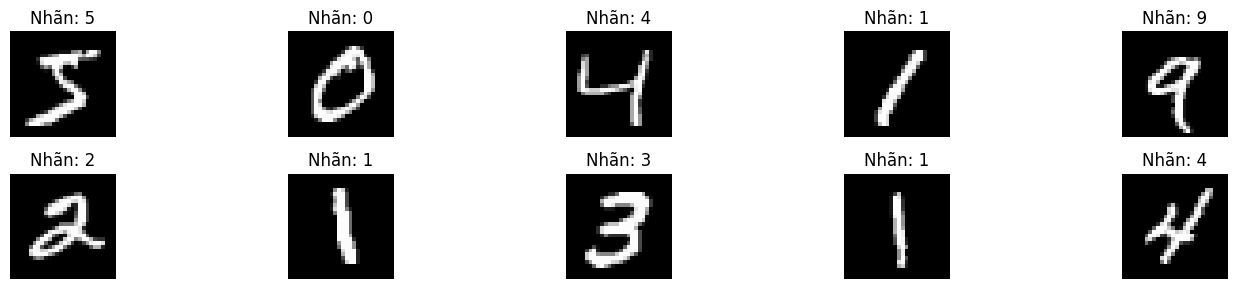

In [37]:
def show_samples(dataset: Dataset, number_of_samples: int = 10) -> None:
    """Hiển thị một số mẫu đầu tiên trong dataset."""
    number_of_samples = min(number_of_samples, len(dataset))

    plt.figure(figsize=(15, 3))
    for index in range(number_of_samples):
        image, label = dataset[index]
        plt.subplot(2, 5, index + 1)
        plt.imshow(image.numpy(), cmap="gray")
        plt.title(f"Nhãn: {label.item()}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


show_samples(full_train_dataset)

## 6. Chia train set và validation set

MNIST cung cấp sẵn:

- 60.000 mẫu train.
- 10.000 mẫu test.

Ta tiếp tục lấy 10% dữ liệu train làm validation:

- 90% để cập nhật trọng số.
- 10% để lựa chọn mô hình tốt nhất.

`random_split` được cung cấp một `Generator` có seed để lần sau vẫn chia đúng các mẫu như cũ.

In [38]:
VALIDATION_RATIO = 0.10

validation_size = int(len(full_train_dataset) * VALIDATION_RATIO)
train_size = len(full_train_dataset) - validation_size

train_dataset, validation_dataset = random_split(
    full_train_dataset,
    lengths=[train_size, validation_size],
    generator=torch.Generator().manual_seed(SEED),
)

print(f"Train set:      {len(train_dataset):,} mẫu")
print(f"Validation set: {len(validation_dataset):,} mẫu")
print(f"Test set:       {len(test_dataset):,} mẫu")

Train set:      54,000 mẫu
Validation set: 6,000 mẫu
Test set:       10,000 mẫu


## 7. Tạo `DataLoader`

`DataLoader` có ba nhiệm vụ chính:

1. Gom nhiều mẫu thành một batch.
2. Xáo trộn dữ liệu train.
3. Lặp qua dữ liệu thuận tiện.

### Batch là gì?

Thay vì đưa toàn bộ 54.000 ảnh vào mô hình cùng lúc, ta chia thành các nhóm nhỏ. Với `batch_size=64`, mỗi lần mô hình xử lý tối đa 64 ảnh.

### Vì sao chỉ `shuffle=True` với train set?

- Train set cần xáo trộn để các batch thay đổi qua từng epoch.
- Validation và test không cập nhật trọng số nên không cần xáo trộn.

In [39]:
BATCH_SIZE = 64
PIN_MEMORY = device.type == "cuda"

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=PIN_MEMORY,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=PIN_MEMORY,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=PIN_MEMORY,
)

sample_images, sample_labels = next(iter(train_loader))
print(f"Shape của batch ảnh: {sample_images.shape}")
print(f"Shape của batch nhãn: {sample_labels.shape}")
print(f"Số batch train mỗi epoch: {len(train_loader)}")

Shape của batch ảnh: torch.Size([64, 28, 28])
Shape của batch nhãn: torch.Size([64])
Số batch train mỗi epoch: 844


## 8. Lý thuyết mô hình

### 8.1. Mô hình tuyến tính một lớp

Ảnh `28 × 28` được trải phẳng thành vector 784 phần tử. Mô hình tính:

\[
\mathbf{z} = \mathbf{xW} + \mathbf{b}
\]

Trong đó `z` gồm 10 số, mỗi số là điểm cho một lớp. Các điểm này gọi là **logits**.

Mô hình tuyến tính không có hidden layer nên khả năng biểu diễn còn hạn chế. Tuy nhiên đây là baseline tốt vì đơn giản, nhanh và giúp so sánh với mô hình phức tạp hơn.

### 8.2. MLP ba lớp

Cấu trúc:

```text
784 → 256 → 128 → 10
```

- `Linear`: học phép biến đổi tuyến tính.
- `ReLU`: tạo tính phi tuyến; nếu thiếu ReLU, nhiều lớp Linear liên tiếp vẫn tương đương một lớp Linear.
- `Dropout`: ngẫu nhiên tắt một phần neuron khi train để giảm phụ thuộc quá mức vào một nhóm đặc trưng.
- Lớp cuối không dùng Softmax vì `CrossEntropyLoss` đã xử lý bước này theo cách ổn định số học.

In [40]:
class LinearClassifier(nn.Module):
    """Baseline: mô hình phân loại tuyến tính một lớp."""

    def __init__(self, input_dim: int = 28 * 28, num_classes: int = 10) -> None:
        super().__init__()
        self.classifier = nn.Linear(input_dim, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.flatten(start_dim=1)
        logits = self.classifier(x)
        return logits


class MLPClassifier(nn.Module):
    """MLP gồm hai hidden layer và một output layer."""

    def __init__(
        self,
        input_dim: int = 28 * 28,
        hidden_dim_1: int = 256,
        hidden_dim_2: int = 128,
        num_classes: int = 10,
        dropout_rate: float = 0.20,
    ) -> None:
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, hidden_dim_1),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim_1, hidden_dim_2),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim_2, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        logits = self.network(x)
        return logits


def count_trainable_parameters(model: nn.Module) -> int:
    """Đếm số tham số được cập nhật trong quá trình huấn luyện."""
    return sum(parameter.numel() for parameter in model.parameters()
               if parameter.requires_grad)

## 9. Chọn mô hình và siêu tham số

Sinh viên có thể đổi `MODEL_NAME` thành:

- `"linear"`: mô hình tuyến tính.
- `"mlp"`: mạng ba lớp.

### Một số siêu tham số

- `EPOCHS`: số lần mô hình đi qua toàn bộ train set.
- `LEARNING_RATE`: độ lớn của bước cập nhật trọng số.
- `PATIENCE`: số epoch chờ validation F1 cải thiện trước khi dừng sớm.

Notebook dùng Adam vì optimizer này thường ổn định và dễ bắt đầu với người mới. Khi đã hiểu rõ hơn, sinh viên nên thử SGD để so sánh.

In [41]:
MODEL_NAME = "linear"          # Chọn "linear" hoặc "mlp"
EPOCHS = 15
LEARNING_RATE = 1e-3
PATIENCE = 4

if MODEL_NAME == "linear":
    model = LinearClassifier()
elif MODEL_NAME == "mlp":
    model = MLPClassifier()
else:
    raise ValueError("MODEL_NAME chỉ nhận 'linear' hoặc 'mlp'.")

model = model.to(device)

print(model)
print(f"Số tham số có thể học: {count_trainable_parameters(model):,}")

LinearClassifier(
  (classifier): Linear(in_features=784, out_features=10, bias=True)
)
Số tham số có thể học: 7,850


## 10. Loss function và optimizer

### `CrossEntropyLoss`

Trong bài toán phân loại nhiều lớp, loss đo mức độ sai giữa logits và nhãn thật. Loss càng nhỏ thì dự đoán càng phù hợp với nhãn.

**Lưu ý quan trọng:**

- Đầu ra của mô hình là logits, chưa cần Softmax.
- Nhãn thật là số nguyên từ 0 đến 9.

### Optimizer

Optimizer dùng gradient do `loss.backward()` tính được để cập nhật trọng số. Chu trình cơ bản:

```python
optimizer.zero_grad()
logits = model(images)
loss = loss_fn(logits, labels)
loss.backward()
optimizer.step()
```

In [42]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

CHECKPOINT_PATH = Path(f"best_{MODEL_NAME}_mnist.pth")
print(f"Checkpoint sẽ được lưu tại: {CHECKPOINT_PATH.resolve()}")

Checkpoint sẽ được lưu tại: C:\Users\Admin\Desktop\UIT-2025\HocTap\DS\DS201_DL_FOR_DS\Deep-Learning-trong-Khoa-hoc-du-lieu-main\LAB1\best_linear_mnist.pth


## 11. Hàm huấn luyện một epoch

### Vì sao cần `model.train()`?

`model.train()` đưa mô hình vào chế độ huấn luyện. Với Dropout, một số neuron sẽ được tắt ngẫu nhiên ở chế độ này.

### Vì sao phải xóa gradient?

PyTorch mặc định cộng dồn gradient. Nếu không gọi `optimizer.zero_grad()`, gradient của batch mới sẽ cộng với gradient cũ, làm sai quá trình cập nhật.

### Vì sao trả về loss trung bình theo số mẫu?

Batch cuối có thể ít hơn các batch khác. Nhân loss của mỗi batch với số mẫu rồi chia tổng số mẫu sẽ cho trung bình chính xác hơn.

In [43]:
def train_one_epoch(
    dataloader: DataLoader,
    model: nn.Module,
    loss_fn: nn.Module,
    optimizer: torch.optim.Optimizer,
    device: torch.device,
) -> float:
    """Huấn luyện mô hình đúng một epoch và trả về loss trung bình."""
    model.train()

    total_loss = 0.0
    total_samples = 0

    for images, labels in dataloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = loss_fn(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples

## 12. Hàm đánh giá

Khi đánh giá, mô hình không được cập nhật trọng số.

- `model.eval()` tắt hành vi ngẫu nhiên của Dropout.
- `torch.inference_mode()` tắt việc lưu đồ thị gradient, giúp tiết kiệm bộ nhớ và chạy nhanh hơn.
- `argmax(dim=1)` chọn lớp có logit lớn nhất.

### Các chỉ số

- **Accuracy**: tỷ lệ dự đoán đúng trên toàn bộ mẫu.
- **Precision**: trong các mẫu được dự đoán là một lớp, có bao nhiêu mẫu đúng.
- **Recall**: trong các mẫu thật sự thuộc một lớp, mô hình tìm đúng bao nhiêu mẫu.
- **F1-score**: trung bình điều hòa của precision và recall.

Notebook dùng `average="macro"`, tức là tính riêng từng lớp rồi lấy trung bình. Mỗi lớp có vai trò ngang nhau.

In [44]:
def evaluate(
    dataloader: DataLoader,
    model: nn.Module,
    loss_fn: nn.Module,
    device: torch.device,
) -> dict:
    """Đánh giá mô hình và trả về loss, metrics cùng dự đoán."""
    model.eval()

    total_loss = 0.0
    total_samples = 0
    all_labels = []
    all_predictions = []

    with torch.inference_mode():
        for images, labels in dataloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = model(images)
            loss = loss_fn(logits, labels)
            predictions = logits.argmax(dim=1)

            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    all_labels = np.asarray(all_labels)
    all_predictions = np.asarray(all_predictions)

    return {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(all_labels, all_predictions),
        "precision": precision_score(
            all_labels,
            all_predictions,
            average="macro",
            zero_division=0,
        ),
        "recall": recall_score(
            all_labels,
            all_predictions,
            average="macro",
            zero_division=0,
        ),
        "f1": f1_score(
            all_labels,
            all_predictions,
            average="macro",
            zero_division=0,
        ),
        "labels": all_labels,
        "predictions": all_predictions,
    }

## 13. Huấn luyện và lưu mô hình tốt nhất

Sau mỗi epoch:

1. Huấn luyện trên train set.
2. Đánh giá trên validation set.
3. Nếu validation F1 tốt hơn trước, lưu trọng số.
4. Nếu F1 không cải thiện trong nhiều epoch liên tiếp, dừng sớm.

### Vì sao chọn checkpoint theo validation F1?

Checkpoint nên được chọn bằng dữ liệu mà mô hình không trực tiếp học. F1 macro cũng quan sát đồng đều cả 10 lớp thay vì chỉ nhìn tổng số dự đoán đúng.

In [45]:
history = {
    "train_loss": [],
    "validation_loss": [],
    "validation_accuracy": [],
    "validation_f1": [],
}

best_validation_f1 = -np.inf
epochs_without_improvement = 0
training_start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(
        train_loader,
        model,
        loss_fn,
        optimizer,
        device,
    )

    validation_result = evaluate(
        validation_loader,
        model,
        loss_fn,
        device,
    )

    history["train_loss"].append(train_loss)
    history["validation_loss"].append(validation_result["loss"])
    history["validation_accuracy"].append(validation_result["accuracy"])
    history["validation_f1"].append(validation_result["f1"])

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {validation_result['loss']:.4f} | "
        f"Val accuracy: {validation_result['accuracy'] * 100:.2f}% | "
        f"Val F1: {validation_result['f1'] * 100:.2f}%"
    )

    if validation_result["f1"] > best_validation_f1:
        best_validation_f1 = validation_result["f1"]
        epochs_without_improvement = 0

        torch.save(
            {
                "model_name": MODEL_NAME,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_validation_f1": best_validation_f1,
                "epoch": epoch,
            },
            CHECKPOINT_PATH,
        )
        print("  ↳ Đã lưu checkpoint tốt nhất.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(
            f"Dừng sớm vì validation F1 không cải thiện "
            f"trong {PATIENCE} epoch liên tiếp."
        )
        break

training_time = time.time() - training_start_time
print(f"\nThời gian huấn luyện: {training_time:.1f} giây")
print(f"Validation F1 tốt nhất: {best_validation_f1 * 100:.2f}%")

Epoch 01/15 | Train loss: 0.5651 | Val loss: 0.3647 | Val accuracy: 90.15% | Val F1: 89.98%
  ↳ Đã lưu checkpoint tốt nhất.
Epoch 02/15 | Train loss: 0.3292 | Val loss: 0.3210 | Val accuracy: 90.83% | Val F1: 90.68%
  ↳ Đã lưu checkpoint tốt nhất.
Epoch 03/15 | Train loss: 0.2987 | Val loss: 0.3046 | Val accuracy: 91.30% | Val F1: 91.16%
  ↳ Đã lưu checkpoint tốt nhất.
Epoch 04/15 | Train loss: 0.2838 | Val loss: 0.3011 | Val accuracy: 91.42% | Val F1: 91.25%
  ↳ Đã lưu checkpoint tốt nhất.
Epoch 05/15 | Train loss: 0.2745 | Val loss: 0.2941 | Val accuracy: 91.42% | Val F1: 91.28%
  ↳ Đã lưu checkpoint tốt nhất.
Epoch 06/15 | Train loss: 0.2681 | Val loss: 0.2921 | Val accuracy: 91.67% | Val F1: 91.52%
  ↳ Đã lưu checkpoint tốt nhất.
Epoch 07/15 | Train loss: 0.2628 | Val loss: 0.2906 | Val accuracy: 91.67% | Val F1: 91.53%
  ↳ Đã lưu checkpoint tốt nhất.
Epoch 08/15 | Train loss: 0.2598 | Val loss: 0.2875 | Val accuracy: 91.83% | Val F1: 91.69%
  ↳ Đã lưu checkpoint tốt nhất.
Epoch 09

## 14. Vẽ biểu đồ quá trình học

Một mô hình học tốt thường có:

- Train loss giảm dần.
- Validation loss giảm hoặc ổn định.
- Validation F1 tăng rồi dần bão hòa.

Nếu train loss tiếp tục giảm nhưng validation loss tăng mạnh, mô hình có thể đang **overfitting**.

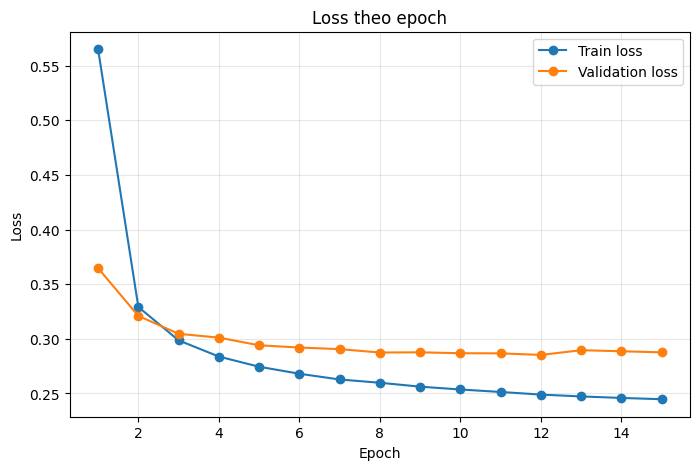

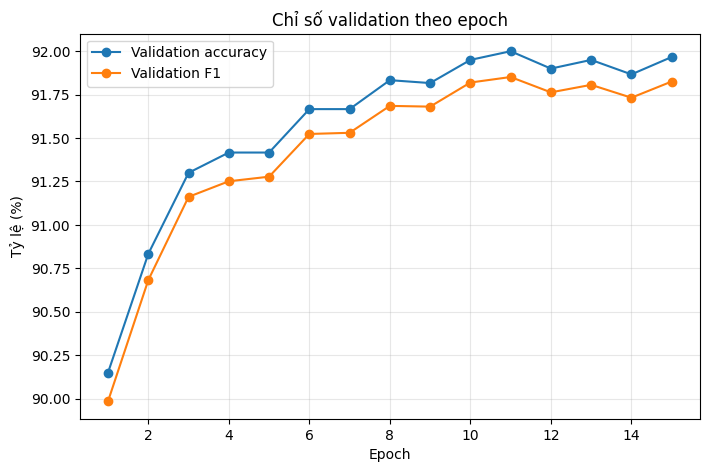

In [46]:
epoch_numbers = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epoch_numbers, history["train_loss"], marker="o", label="Train loss")
plt.plot(
    epoch_numbers,
    history["validation_loss"],
    marker="o",
    label="Validation loss",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss theo epoch")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    epoch_numbers,
    np.array(history["validation_accuracy"]) * 100,
    marker="o",
    label="Validation accuracy",
)
plt.plot(
    epoch_numbers,
    np.array(history["validation_f1"]) * 100,
    marker="o",
    label="Validation F1",
)
plt.xlabel("Epoch")
plt.ylabel("Tỷ lệ (%)")
plt.title("Chỉ số validation theo epoch")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 15. Tải lại checkpoint tốt nhất

Mô hình đang nằm trong biến `model` sau vòng lặp là mô hình của epoch cuối, chưa chắc là mô hình tốt nhất.

Vì vậy, trước khi đánh giá test set, phải tải lại checkpoint có validation F1 cao nhất.

In [47]:
try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=device,
        weights_only=True,
    )
except TypeError:
    # Tương thích với một số phiên bản PyTorch cũ chưa có tham số weights_only.
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"Đã tải checkpoint tại epoch: {checkpoint['epoch']}")
print(
    "Validation F1 của checkpoint: "
    f"{checkpoint['best_validation_f1'] * 100:.2f}%"
)

Đã tải checkpoint tại epoch: 11
Validation F1 của checkpoint: 91.85%


## 16. Đánh giá cuối cùng trên test set

Đây là lần đầu tiên test set được dùng để báo cáo kết quả mô hình.

Sau bước này, nếu tiếp tục sửa kiến trúc hoặc siêu tham số chỉ vì test score chưa cao, test set cũng sẽ dần trở thành validation set. Trong một thí nghiệm nghiêm túc, cần giữ test set độc lập.

In [48]:
test_result = evaluate(test_loader, model, loss_fn, device)

print("KẾT QUẢ TRÊN TEST SET")
print("-" * 40)
print(f"Test loss:       {test_result['loss']:.4f}")
print(f"Test accuracy:   {test_result['accuracy'] * 100:.2f}%")
print(f"Macro precision: {test_result['precision'] * 100:.2f}%")
print(f"Macro recall:    {test_result['recall'] * 100:.2f}%")
print(f"Macro F1-score:  {test_result['f1'] * 100:.2f}%")

print("\nBáo cáo theo từng lớp:\n")
print(
    classification_report(
        test_result["labels"],
        test_result["predictions"],
        digits=4,
        zero_division=0,
    )
)

KẾT QUẢ TRÊN TEST SET
----------------------------------------
Test loss:       0.2647
Test accuracy:   92.67%
Macro precision: 92.60%
Macro recall:    92.56%
Macro F1-score:  92.56%

Báo cáo theo từng lớp:

              precision    recall  f1-score   support

           0     0.9497    0.9827    0.9659       980
           1     0.9687    0.9806    0.9746      1135
           2     0.9414    0.8866    0.9132      1032
           3     0.9065    0.9119    0.9092      1010
           4     0.9286    0.9399    0.9342       982
           5     0.9116    0.8666    0.8885       892
           6     0.9403    0.9530    0.9466       958
           7     0.9104    0.9387    0.9243      1028
           8     0.8775    0.8973    0.8873       974
           9     0.9255    0.8989    0.9120      1009

    accuracy                         0.9267     10000
   macro avg     0.9260    0.9256    0.9256     10000
weighted avg     0.9267    0.9267    0.9265     10000



## 17. Confusion matrix

Confusion matrix cho biết mỗi lớp thật thường bị dự đoán nhầm thành lớp nào.

- Hàng: nhãn thật.
- Cột: nhãn dự đoán.
- Đường chéo chính: dự đoán đúng.

Một con số lớn nằm ngoài đường chéo cho thấy cặp chữ số mà mô hình thường nhầm lẫn.

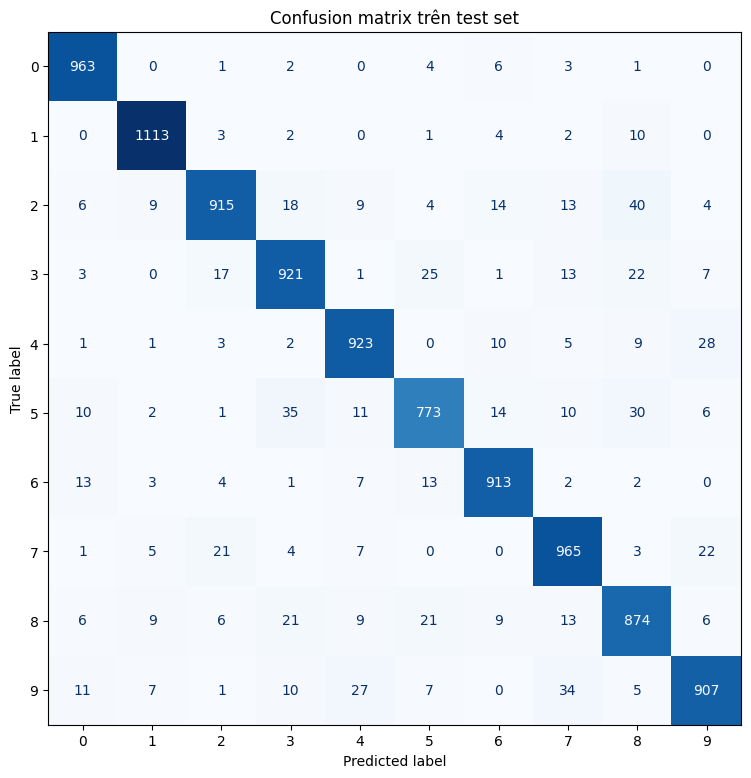

In [49]:
fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay.from_predictions(
    test_result["labels"],
    test_result["predictions"],
    labels=np.arange(10),
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False,
)
ax.set_title("Confusion matrix trên test set")
plt.show()

## 18. Xem một số mẫu dự đoán sai

Chỉ số tổng hợp không cho biết nguyên nhân cụ thể. Xem trực tiếp ảnh sai giúp đặt câu hỏi:

- Chữ số có được viết quá méo không?
- Hai lớp có hình dạng gần giống nhau không?
- Mô hình có xu hướng nhầm theo một hướng nhất định không?

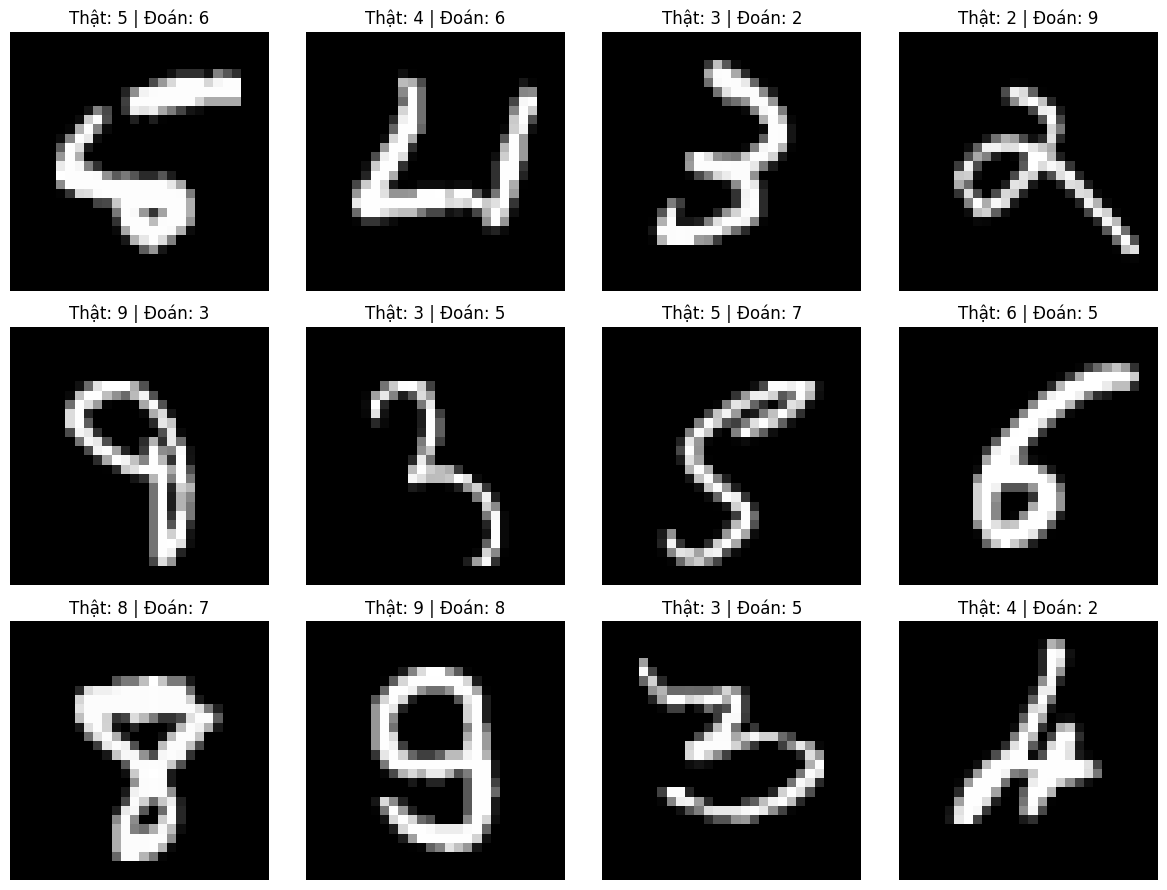

In [50]:
def show_misclassified_samples(
    dataset: Dataset,
    labels: np.ndarray,
    predictions: np.ndarray,
    number_of_samples: int = 12,
) -> None:
    wrong_indices = np.where(labels != predictions)[0]

    if len(wrong_indices) == 0:
        print("Không có mẫu dự đoán sai.")
        return

    number_of_samples = min(number_of_samples, len(wrong_indices))
    selected_indices = wrong_indices[:number_of_samples]

    rows = 3
    columns = 4
    plt.figure(figsize=(12, 9))

    for plot_index, dataset_index in enumerate(selected_indices):
        image, true_label = dataset[int(dataset_index)]
        predicted_label = predictions[dataset_index]

        plt.subplot(rows, columns, plot_index + 1)
        plt.imshow(image.numpy(), cmap="gray")
        plt.title(
            f"Thật: {true_label.item()} | Đoán: {predicted_label}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()


show_misclassified_samples(
    test_dataset,
    test_result["labels"],
    test_result["predictions"],
)

## 19. Thử dự đoán một ảnh đơn lẻ

Khi dự đoán một ảnh, mô hình vẫn mong đợi đầu vào có chiều batch. Vì vậy cần `unsqueeze(0)` để biến ảnh `[28, 28]` thành `[1, 28, 28]`.

Softmax chỉ được dùng ở bước trình bày xác suất cho người đọc, không dùng trước `CrossEntropyLoss` khi huấn luyện.

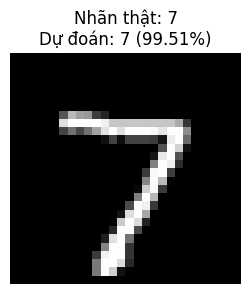

In [51]:
def predict_one_image(
    model: nn.Module,
    image: torch.Tensor,
    device: torch.device,
) -> tuple[int, float]:
    model.eval()

    image_batch = image.unsqueeze(0).to(device)

    with torch.inference_mode():
        logits = model(image_batch)
        probabilities = torch.softmax(logits, dim=1)
        confidence, predicted_class = probabilities.max(dim=1)

    return predicted_class.item(), confidence.item()


sample_index = 0
sample_image, sample_label = test_dataset[sample_index]
predicted_class, confidence = predict_one_image(model, sample_image, device)

plt.figure(figsize=(3, 3))
plt.imshow(sample_image.numpy(), cmap="gray")
plt.title(
    f"Nhãn thật: {sample_label.item()}\n"
    f"Dự đoán: {predicted_class} ({confidence * 100:.2f}%)"
)
plt.axis("off")
plt.show()

## 20. Tổng kết kiến thức

### Quy trình đúng

1. Kiểm tra và chuẩn hóa dữ liệu.
2. Chia train, validation và test.
3. Tạo DataLoader.
4. Xây dựng mô hình trả về logits.
5. Dùng `CrossEntropyLoss`.
6. Huấn luyện với `model.train()`.
7. Đánh giá với `model.eval()` và không tính gradient.
8. Chọn checkpoint theo validation set.
9. Tải lại checkpoint tốt nhất.
10. Chỉ dùng test set để báo cáo cuối cùng.

### Những lỗi người mới thường gặp

- Dùng test set sau mỗi epoch.
- Thêm Softmax trước `CrossEntropyLoss`.
- Quên `optimizer.zero_grad()`.
- Quên chuyển cả model và tensor lên cùng thiết bị.
- Quên `model.eval()` khi đánh giá.
- Chỉ lưu epoch cuối thay vì epoch tốt nhất.
- Không đặt seed nên khó so sánh kết quả.
- Chỉ nhìn accuracy mà không phân tích từng lớp.

---

## Bài tập mở rộng

1. Chạy mô hình `linear` và `mlp`, lập bảng so sánh số tham số, thời gian và F1-score.
2. Thử các learning rate: `1e-2`, `1e-3`, `1e-4`.
3. Thử bỏ Dropout và nhận xét hiện tượng overfitting.
4. Đổi optimizer từ Adam sang SGD:

```python
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0.9,
)
```

5. Tìm ba cặp chữ số bị nhầm nhiều nhất từ confusion matrix.
6. Viết CNN đơn giản và so sánh với MLP.

### Câu hỏi tự kiểm tra

- Vì sao output layer có 10 neuron?
- Vì sao ảnh phải được flatten trước khi đi vào `Linear`?
- ReLU giải quyết vấn đề gì?
- Tại sao không dùng test set để chọn epoch?
- `model.train()` và `model.eval()` khác nhau như thế nào?
- Vì sao `CrossEntropyLoss` không cần Softmax ở đầu ra?